# Synaptic scaling 
These notes investigate synaptic scaling and its effect on synaptic dynamics. 
We will run a stochastic trajectory for each synapse, as it could be learning in absence of stimuli, and test how the homeostatic mechanism (synaptic scaling) transforms the original synaptic values.

Take a system of N neurons, where $W_{ij}$ is the synaptic weight between the pre-synaptic neuron $i$ and the post-synaptic neuron $j$. 
The total synaptic mass is defined by the initial conditions:
 
$\bar A_i = \sum_j^N W_{ij}$

The synapses will evolve following a trajectory $W_{ij} (t)$ which in our case is governed by the stochastic process $x(t)$. During awake time, driven by external inputs, the circuit will favor synaptic potentiation. In order to maintain the circuit in a functional dynamic range, a homeostatic plasticity is needed. The homeostatic plastivity investigated here is synaptic scaling. Synaptic scaling hypothesizes after ac certain number of cycles, the synapses are down/up-scaled such that the total synaptic mass is conserved.

There are two forms of scaling:

__Additive scaling:__
     
$W'_{ij} = W_{ij} - \frac{\sum_j W_{ij} - \bar A_i}{N}$

__Multiplicative scaling:__
    
$W'_{ij} = W_{ij} \frac{\bar A_i}{\sum_j W_{ij}}$


The synaptic evolution is modeled with a Orstein-Uhlenback $x(t)$ dynamics with correlated noise.
The Orstein-Uhlenback allows the synapses to evolve towards a target value, which is modeled via the bias of the process $x_f$.

$r = \alpha  r_{-1} + \xi (\alpha-1)$

$x_{i_+1} =\theta (x_f -x_{i}) + \sigma r$


_parameterization_:

$\alpha$: noise correlation

$\theta$: drift strength

$x_f$: bias

$\sigma$ noise strength


#### Scaling dynamics

Let's assume the variation $\delta_{j}$. 

$W'_{ij} = W_{ij}+\delta_j$ and $\bar A_i = \sum_j^N W_{ij}$


For _additive scaling_

$W'_{ij} <= W_{ij}+\delta_j + \left( \frac{\sum_j W_{ij} - \sum_J W_{ij} +\delta_j}{N}  \right)$
$= W_{ij}+\delta_j - \left( \frac{\sum \delta_j }{N} \right)$ 

then the variation of the weights under scaling is independent of the weight:

$dW_{ij} = \delta_j - \left( \frac{\sum \delta_j }{N} \right)$ 

For _multiplicative scaling_

$W'_{ij} <= (W_{ij}+\delta_j)  \frac{\sum_j W_{ij}}{\sum_j W_{ij} + \sum_j \delta_j} =  \left(W_{ij} + \delta_j\right) \beta$ 

with $\beta =  \frac{\sum_j W_{ij}}{\sum_j W_{ij} + \sum_j \delta_j}$, 

for small perturbations $\beta = \left(1 - \frac{\sum_j \delta_j}{\sum_j W_{ij} }\right)$

We can rewrite it with $\gamma = 1 - \beta$ and then the weight variation is:

$dW_{ij} = \left(W_{ij} \gamma \right)+  \delta_j (1-\gamma)$

Hence this scaling is proportional to Wij and we are in the situation described here:

C. Tetzlaff, C. Kolodziejski, M. Timme, and F. Wörgötter, ‘Synaptic Scaling in Combination with Many Generic Plasticity Mechanisms Stabilizes Circuit Connectivity’, Frontiers in Computational Neuroscience, vol. 5, p. 47, 2011, doi: 10/cjbp36.





$dW_{ij} = \delta_j - \left( \frac{\sum \delta_j }{N} \right)$ 


In [1]:
#In the following I will use the _scaling_routines_ defined in 
include("scaling.jl");

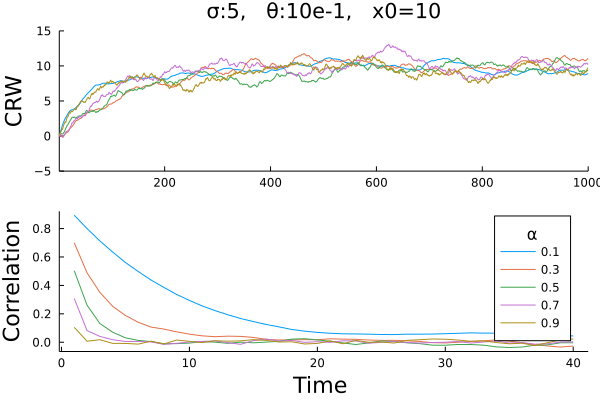

In [2]:
p,q = plot(ylabel="CRW", xlabel=""), plot(ylabel="Correlation", xlabel="Time ")

time=10000
for α in   0.1:0.2:1.
    x = Particle{Float32}(0.)
    w = zeros(Float32, time)
    ξ = zeros(Float32, time)
    for n in 2:time
        CRW!(x;α=Float32(α), σ=5f0, θ=1f-1,x0=10f0)
        w[n] = x.μ
        ξ[n] = x.ξ
    end
    plot!(p, w, labels="", xlims=(1,1000), ylims=(-5,15))
#     plot!(q, ξ, labels="")

    plot!(q,autocor(ξ,1:1:40), labels=α, legendtitle="α")
end

title!(p, "σ:5,   θ:10e-1,   x0=10")
pp = plot(p,q, layout=(2,1))


To quantify the similarity between the target state and the actual synaptic state, we use tow different measures

### The relative displacement.
It measures the relative distance between each synapses and its initial state, or target. 

$\Delta= \sum_j^N \frac{\left( W_{ij} - \bar W_{ij}\right) ^2}{N}$

### The normalized-MSE.
It measures the mean squared error between the actual state and target states, synapses are normalized so that the constraints in synaptic mass does not affect the measure. 

$a_{ij} = \frac{W_{ij} - \min{W_{ij}}}{\max{W_ij}}$

$MSE= \sum_j^N \frac{\left(a_{ij} - \bar a_{ij}\right)^2}{N}$

In [18]:
# include(joinpath(@__DIR__,"noscaling_examples.jl"));

function displacement(w, w_target)
    sum(abs.(w .- w_target)./w_target)/length(w)
end


function MSE(w,target)
    f(x) = x .- minimum(x)|> x->x ./maximum(x) 
    return sum((f(w).-f(target)).^2 )/length(w)
end

z = rand(1,1000)
m = rand(1,1000)
z[1,1] = 0
m[1,1] = 1
MSE(z,m)
MSD(z,m)
# plot(
# scatter(z'),
# scatter(m')
# )




UndefVarError: UndefVarError: MSD not defined

We can evaluate the effect of scaling on MSE by inserting the relative update equations in the equation for MSE.

In the limit os small perturbations, the re-scaling of the MSE is negligible and the approximation for $\beta$ is valid. 

__Multiplicative__

$MSE = \frac{\sum_j \left(W_{ij} - \left(W_{ij} + \delta_j\right)\beta \right)^2 }{N}$ 
$= \frac{\sum_j \left( (1-\beta) W_{ij} + \delta_j  \beta \right)^2}{N}$ 
$= \frac{\sum_j \left( (1-\beta) W_{ij}\right)^2 + \left(\delta_j  \beta \right)^2 + 2\left((1-\beta) W_{ij} + \delta_j  \beta \right)}{N} = ...$ 

__Additive__

$MSE = \frac{\sum_j \left(W_{ij} - \left(W_{ij} + \delta_j\right) + \frac{\sum \delta_j }{N} \right)^2 }{N}$ 
$= \frac{\sum_j \left(\delta_j + \frac{\sum \delta_j }{N}\right)^2}{N}$ 
$= \frac{\sum_j \delta_j^2 + \left(\frac{\sum \delta_j }{N} \right)^2 + 2\left(\delta_j + \frac{\sum \delta_j }{N} \right)}{N} = ...$ 



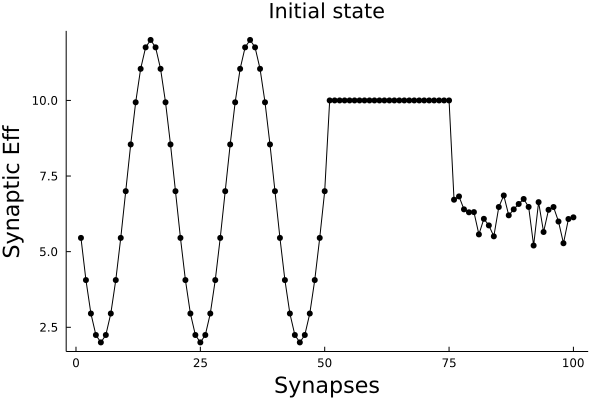

In [4]:

bias = BlockArray(zeros(Float32,1,100),[1],[50,25,25])
bias[Block(1,2)] = fill!(zeros(1,25),10)
bias[Block(1,3)] = 2*rand(1,25).+5
# bias[Block(1,1)] 
bias[1,1:50]= let 
    a = zeros(Float32, 1,50) ; 
    a[1,:] .=[5sin(x*2π/20+π).+7 for x in 1:50]
end;

plot(bias', label="", c=:black)
scatter!(bias', title="Initial state", ylabel="Synaptic Eff", serietype=:scatter, xlabel="Synapses", label="", c=:black)

### Synaptic evolution without scaling

Run examples of synaptic evolution without scaling and measure the displacement from the target state.

In the first example, the synapses evolve randomly from a structured initial state, without trarget dynamics. This example correspnd to a network which is receiving non meaningful inputs.


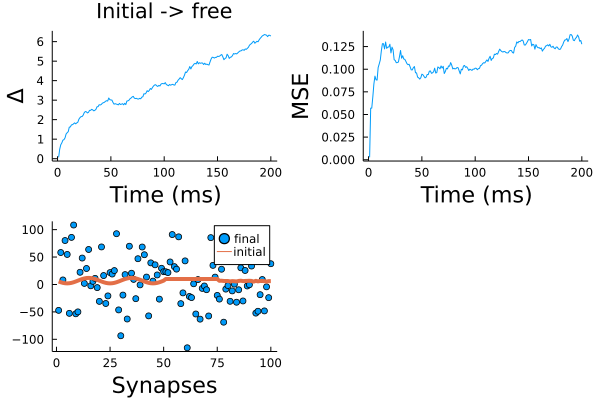

In [5]:
update!(w,bias) = CRW!(w, α=0.5f0, σ=5f0, θ=0f0, x0=bias)

include("scaling.jl")
w = Matrix(bias)
Δ = []
M = []
for x in 1:10000
    w = run_noscaling(w, bias,10)
    push!(Δ, displacement(w,Matrix(bias)))
    push!(M, MSE(w,Matrix(bias)))
end


plot(
    plot(Δ[1:50:10_000], ylabel="Δ", xlabel="Time (ms)", label="",title="Initial -> free"),
    plot(M[1:50:10_000], ylabel="MSE", xlabel="Time (ms)", label=""),
    scatter(w',label="final") |> x-> plot!(x,bias',label="initial", xlabel="Synapses", lw=4)
    )

In the second, the dynamics evolves randomly from a structured initial state, towards a structured final state, without trarget dynamics. 
This example correspnd to a network which is receiving forced to remain in a certain state, with noise.


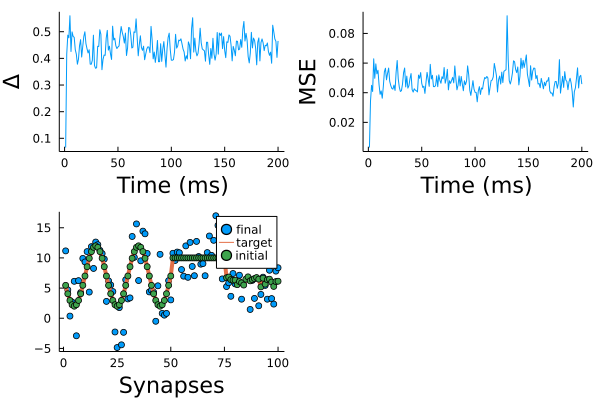

In [6]:
update!(w,bias) = CRW!(w, α=0.5f0, σ=5f0, θ=0.1f-1, x0=bias)

include("scaling.jl")
w = Matrix(bias)
Δ = []
M = []
for x in 1:10000
    w = run_noscaling(w, bias,10)
    push!(Δ, displacement(w,Matrix(bias)))
    push!(M, MSE(w,Matrix(bias)))
end

plot(
    plot(Δ[1:50:10_000], ylabel="Δ", xlabel="Time (ms)", label=""),
    plot(M[1:50:10_000], ylabel="MSE", xlabel="Time (ms)", label=""),
    scatter(w',label="final", xlabel="Synapses")|>x->plot!(x,bias',label="target", lw=4) |>x->scatter!(x,bias',label="initial")
    )


Eventiually, the dynamics evolve from a random initial state towards a target state. 

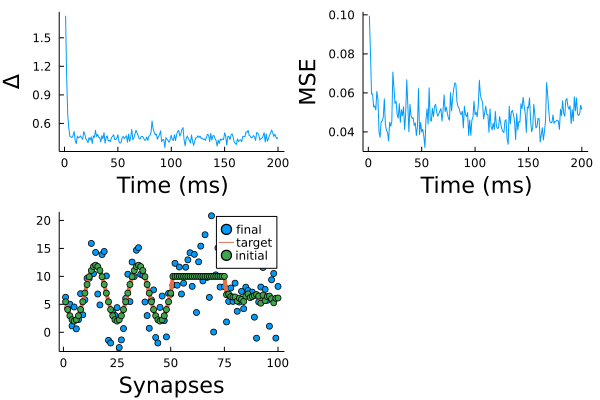

In [7]:
update!(w,bias) = CRW!(w, α=0.5f0, σ=5f0, θ=0.1f-1, x0=bias)

include("scaling.jl")
w0 = Matrix(rand(1,100).+15)
w = w0
Δ = []
M = []
for x in 1:10000
    w = run_noscaling(w, bias,10)
    push!(Δ, displacement(w,Matrix(bias)))

    push!(M, MSE(w,Matrix(bias)))
end

plot(
    plot(Δ[1:50:10_000], ylabel="Δ", xlabel="Time (ms)", label=""),
    plot(M[1:50:10_000], ylabel="MSE", xlabel="Time (ms)", label=""),
    scatter(w',label="final", xlabel="Synapses")|>x->plot!(x,bias',label="target", lw=4) |>x->scatter!(x,bias',label="initial")
    )

### First conclusions

The displacement $\Delta$ is limited when there is a target state. 
The MSE is always limited. For free synaptic evolution it approaches 0.1, for the forced synapses case it approaches 0.05.

The magnitude of the relative displacement depends on the parameters of the CRW. 
With the parameters used, $\lim_{n->\infty} \Delta=0.5$


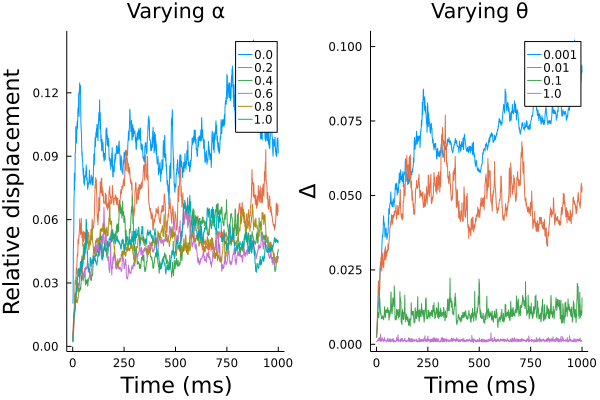

In [8]:

p = plot()
for x in 0.0:0.2:1.
    Δ = []
    update!(w,bias) = CRW!(w, α=Float32(x), σ=5f0, θ=1f-2, x0=bias)
    w = Matrix(bias)
    for x in 1:1000
        w = run_noscaling(w, bias,10)
        push!(Δ, MSE(w,Matrix(bias)))
    end
    plot!(Δ, label=x)
end
plot!(ylabel="Relative displacement", xlabel="Time (ms)", title="Varying α")

q = plot()
for x in [0.001, 0.01, 0.1, 1]
    Δ = []
    update!(w,bias) = CRW!(w, α=0.5f0, σ=5f0, θ=Float32(x), x0=bias)
    w = Matrix(bias)
    for x in 1:1000
        w = run_noscaling(w, bias,10)
        push!(Δ, MSE(w,Matrix(bias)))
    end
    plot!(Δ, label=x)
end
plot!(ylabel="Δ", xlabel="Time (ms)", title="Varying θ")

plot(p,q)


In the following I will use these parameters:

$\alpha = 0.5$:

$\theta = 0.01$

$\sigma = 5$

Synaptic scaling
------------------------

Introduce scaling mechanisms and test their effect on MSE and $\Delta$


First test that the scaling functions are working properly. 

target: [354.39173619273504], init: 1258.3111394424773 
 mult: 354.39173619273527, add: 354.39173619273527

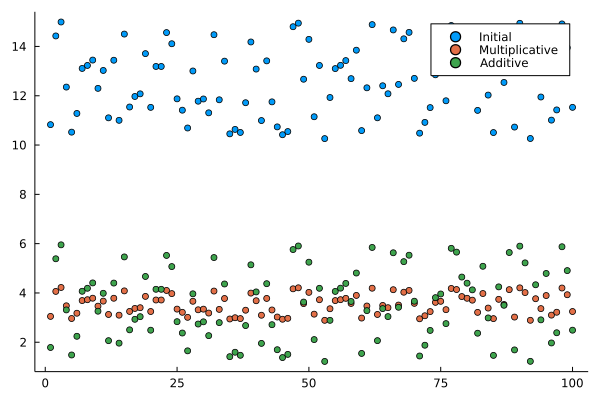

In [9]:
## Test scaling
include("scaling.jl")

initial = Matrix(rand(1,100).*5 .+10)
w0 = rand(1,100).+3

sumwee0 = sum(w0, dims=2)[:,1]

init= sum(initial)
q0 = scatter(initial', label="Initial")
w = Particles(initial)
scaling_mult!(w, sumwee0)
mul = sum(w)
scatter!(getfield.(w,:μ)', label="Multiplicative")

w = Particles(initial)
scaling_add!(w, sumwee0)
add = sum(w)
scatter!(getfield.(w,:μ)', label="Additive")


print("target: $sumwee0, init: $init \n mult: $mul, add: $add")
plot!()


Now run the same set of experiments:

        1. Free synaptic evolution from structured initial state. 
        
        2. Identical structured initial=>final states.
        
        3. Random initial state, structured final state .

In [10]:
w0 = Matrix(bias)
Δadd, Δmul = [], []
Madd, Mmul = [], []

w_mul, w_add = w0, w0
for x in 1:2000
    w_mul,_ = run_scaling(w_mul,scaling_mult!,total_steps=10)
    w_add,_ = run_scaling(w_add,scaling_add!, total_steps=10)
    push!(Δadd, displacement(w_add, w0))
    push!(Δmul, displacement(w_mul, w0))
    push!(Madd, MSE(w_add, w0))
    push!(Mmul, MSE(w_mul, w0))
end

# plot(Δadd, label="Additive")
# plot!(Δmul, label="Multiplicative")
# plot!(legend=:bottom, xlabel="Time (ms)", ylabel="Δ")


In [11]:
p = plot(title="Initial -> free")
p= plot!(bias', lw=3,c=:black, label="Initial")
p= scatter!(w_mul', label="mult")
p= scatter!(w_add', label="additive")

q = plot(Δadd, label="Additive")
plot!(Δmul, label="Multiplicative")
p =plot!(p, xlabel="Synapses", ylabel="Synaptic eff.")

s = plot([Madd,Mmul], label=["Additive" "Multiplicative"], ylabel="MSE")


q = plot!(q, xlabel="Time(ms)", ylabel="Δ")

layout = @layout [
                a{1w}
                grid(1,2)
]
plot(p,q,s, legend=:bottomright, layout=layout)

MethodError: MethodError: Cannot `convert` an object of type Int64 to an object of type Measures.Measure
Closest candidates are:
  convert(::Type{<:Measures.Measure}, !Matched::Float32) at ~/.julia/packages/Plots/FCM0H/src/Plots.jl:169
  convert(::Type{T}, !Matched::T) where T at /usr/share/julia/base/essentials.jl:218

In [12]:
w0 = Matrix(bias)
Δadd, Δmul = [], []
w_mul, w_add = w0, w0
Δadd, Δmul = [], []
Madd, Mmul = [], []

for x in 1:1000
    w_mul,_ = run_scaling(w_mul,scaling_mult!, bias=w0, total_steps=10)
    w_add,_ = run_scaling(w_add,scaling_add!, bias=w0, total_steps=10)
    push!(Δadd, displacement(w_add, w0))
    push!(Δmul, displacement(w_mul, w0))
    push!(Madd, MSE(w_add, w0))
    push!(Mmul, MSE(w_mul, w0))
end

In [13]:

p = plot(title="Initial -> target")
p= plot!(bias', lw=3,c=:black, label="Initial/final")
p= scatter!(w_mul', label="mult")
p= scatter!(w_add', label="additive")

q = plot(Δadd, label="Additive")
plot!(Δmul, label="Multiplicative")
p =plot!(p, xlabel="Synapses", ylabel="Synaptic eff.")

s = plot([Madd,Mmul], label=["Additive" "Multiplicative"], ylabel="MSE")


q = plot!(q, xlabel="Time(ms)", ylabel="Δ")

layout = @layout [
                a{1w}
                grid(1,2)
]
plot(p,q,s, legend=:bottomright, layout=layout)



MethodError: MethodError: Cannot `convert` an object of type Int64 to an object of type Measures.Measure
Closest candidates are:
  convert(::Type{<:Measures.Measure}, !Matched::Float32) at ~/.julia/packages/Plots/FCM0H/src/Plots.jl:169
  convert(::Type{T}, !Matched::T) where T at /usr/share/julia/base/essentials.jl:218

# Realistic model

The last set of example will look into a model where the initial state is random. But the final state is defined (by the inputs and the network goal for example). 

The coefficinet $\beta$ is the ratio between the target state and the initial state. It dictates the homeostatic scaling. If $\beta > 1$, the target state cannot be reached because the synaptic mass is too large.



In [14]:

function run_scaling_compare(β)
    w0 = shuffle(Matrix(bias))

    Δadd, Δmul = [], []
    Madd, Mmul = [], []

    w_mul, w_add = w0, w0
    for x in 1:1000
        w_mul,_ = run_scaling(w_mul,scaling_mult!, bias=bias*β, total_steps=10)
        w_add,_ = run_scaling(w_add,scaling_add!, bias=bias*β, total_steps=10)
        push!(Δadd, displacement(w_add, bias*β))
        push!(Δmul, displacement(w_mul, bias*β))
        push!(Madd, MSE(w_add, bias*β))
        push!(Mmul, MSE(w_mul, bias*β))
    end
    @show sum(w0), sum(bias*β), sum(w_add) sum(w_mul)
    @assert sum(w_mul) - sum(w_add) < 10
    @assert sum(w0) - sum(w_add) <10
    return w_mul, w_add, Δmul[1:5:10_00], Δadd[1:5:10_00], Mmul[1:5:10_00], Madd[1:5:10_00]
end
    
    
    

run_scaling_compare (generic function with 1 method)

In [15]:
β=0.1f0
w_mul, w_add, Δmul, Δadd, Mmul, Madd = run_scaling_compare(β)

p = plot(title="β = $β")
p= plot!(bias', lw=3,c=:black, label="Initial/final")
p= scatter!(w_mul', label="mult")
p= scatter!(w_add', label="additive")

q = plot(Δadd, label="Additive")
plot!(Δmul, label="Multiplicative")
p =plot!(p, xlabel="Synapses", ylabel="Synaptic eff.")

s = plot([Madd,Mmul], label=["Additive" "Multiplicative"], ylabel="MSE")


q = plot!(q, xlabel="Time(ms)", ylabel="Δ")

layout = @layout [
                a{1w}
                grid(1,2)
]
plot(p,q,s, legend=:bottomright, layout=layout)



MethodError: MethodError: Cannot `convert` an object of type Int64 to an object of type Measures.Measure
Closest candidates are:
  convert(::Type{<:Measures.Measure}, !Matched::Float32) at ~/.julia/packages/Plots/FCM0H/src/Plots.jl:169
  convert(::Type{T}, !Matched::T) where T at /usr/share/julia/base/essentials.jl:218

In [16]:
β=1f0
w_mul, w_add, Δmul, Δadd, Mmul, Madd = run_scaling_compare(β)

p = plot(title="β = $β")
p= plot!(bias', lw=3,c=:black, label="Initial/final")
p= scatter!(w_mul', label="mult")
p= scatter!(w_add', label="additive")

q = plot(Δadd, label="Additive")
plot!(Δmul, label="Multiplicative")
p =plot!(p, xlabel="Synapses", ylabel="Synaptic eff.")

s = plot([Madd,Mmul], label=["Additive" "Multiplicative"], ylabel="MSE")


q = plot!(q, xlabel="Time(ms)", ylabel="Δ")

layout = @layout [
                a{1w}
                grid(1,2)
]
plot(p,q,s, legend=:topright, layout=layout)


MethodError: MethodError: Cannot `convert` an object of type Int64 to an object of type Measures.Measure
Closest candidates are:
  convert(::Type{<:Measures.Measure}, !Matched::Float32) at ~/.julia/packages/Plots/FCM0H/src/Plots.jl:169
  convert(::Type{T}, !Matched::T) where T at /usr/share/julia/base/essentials.jl:218

In [17]:
β=1f1
w_mul, w_add, Δmul, Δadd, Mmul, Madd = run_scaling_compare(β)

p = plot(title="β = $β")
p= plot!(bias', lw=3,c=:black, label="final")
p= scatter!(w_mul', label="mult")
p= scatter!(w_add', label="additive")

q = plot(Δadd, label="Additive")
plot!(Δmul, label="Multiplicative")
p =plot!(p, xlabel="Synapses", ylabel="Synaptic eff.")

s = plot([Madd,Mmul], label=["Additive" "Multiplicative"], ylabel="MSE")


q = plot!(q, xlabel="Time(ms)", ylabel="Δ")

layout = @layout [
                a{1w}
                grid(1,2)
]
plot(p,q,s, legend=:right, layout=layout)

MethodError: MethodError: Cannot `convert` an object of type Int64 to an object of type Measures.Measure
Closest candidates are:
  convert(::Type{<:Measures.Measure}, !Matched::Float32) at ~/.julia/packages/Plots/FCM0H/src/Plots.jl:169
  convert(::Type{T}, !Matched::T) where T at /usr/share/julia/base/essentials.jl:218

The last plot is the most instructive one, and the one that makes the result. 
We see that if the target pattern requires larger synapses than the initial state, the synaptic scaling has to actively redistribute the weights among all the synapses. The multiplicative scaling seems to do this better: the target pattern structure is conserved. Conversely, the additive scaling tends to have some points closer to the target,trading it for a more corrupted pattern.